# Lecture 6 - Standard continuous distributions

This notebook connects density, CDF, survival function, quantiles, and simulation for uniform, exponential, and normal laws. The course uses the exponential **rate** parameter; SciPy uses its reciprocal as `scale`.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

SEED = 202606
rng = np.random.default_rng(SEED)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. A density can exceed one

For a uniform law on $[0,0.2]$ seconds, the density is $5$ per second. Probability is represented by **area**, so the density height need not be at most one. The two histograms use the same sample but different bin widths.

density height: 5.0 per second
P(0.04 < X <= 0.09): 0.250
P(X = 0.04) under the continuous model: 0


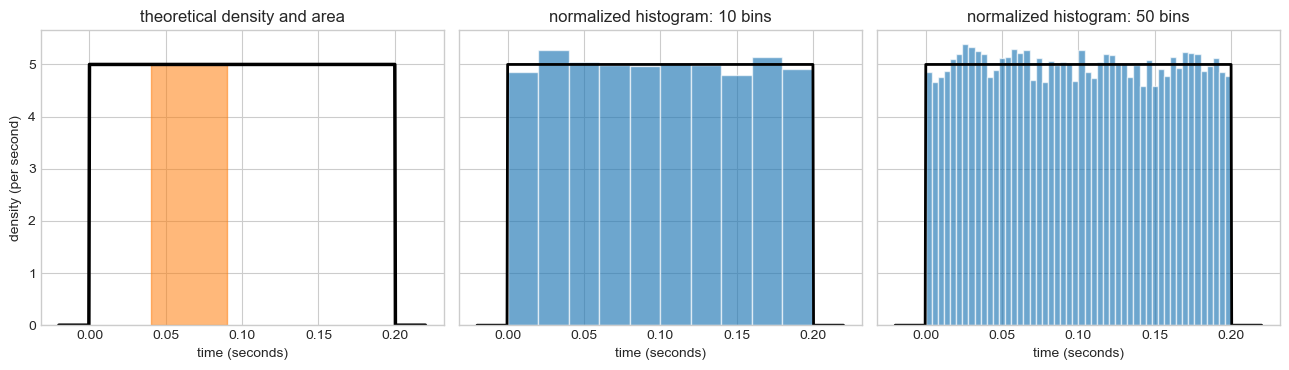

In [30]:
a, b = 0.0, 0.2
short_uniform = stats.uniform(loc=a, scale=b - a)
interval_left, interval_right = 0.04, 0.09
interval_probability = short_uniform.cdf(interval_right) - short_uniform.cdf(interval_left)
print(f"density height: {short_uniform.pdf(0.10):.1f} per second")
print(f"P({interval_left} < X <= {interval_right}): {interval_probability:.3f}")
print(f"P(X = {interval_left}) under the continuous model: 0")

n_samples = 30_000
uniform_sample = short_uniform.rvs(size=n_samples, random_state=rng) # takes draws from continuous random variables.
x_grid = np.linspace(-0.02, 0.22, 600)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
axes[0].plot(x_grid, short_uniform.pdf(x_grid), color="black", linewidth=2.5)
shade_grid = np.linspace(interval_left, interval_right, 150)
axes[0].fill_between(shade_grid, short_uniform.pdf(shade_grid), color="tab:orange", alpha=0.55)
axes[0].set_title("theoretical density and area")
axes[0].set_xlabel("time (seconds)")
axes[0].set_ylabel("density (per second)")

for ax, n_bins in zip(axes[1:], [10, 50]):
    ax.hist(uniform_sample, bins=n_bins, density=True, color="tab:blue", alpha=0.65, edgecolor="white")
    ax.plot(x_grid, short_uniform.pdf(x_grid), color="black", linewidth=2.0)
    ax.set_title(f"normalized histogram: {n_bins} bins")
    ax.set_xlabel("time (seconds)")
plt.tight_layout()
plt.show()

## 2. Three continuous models

The shaded region lies between the 10th and 90th percentiles. Its area is 0.8 in every panel, although the density heights and horizontal scales differ.

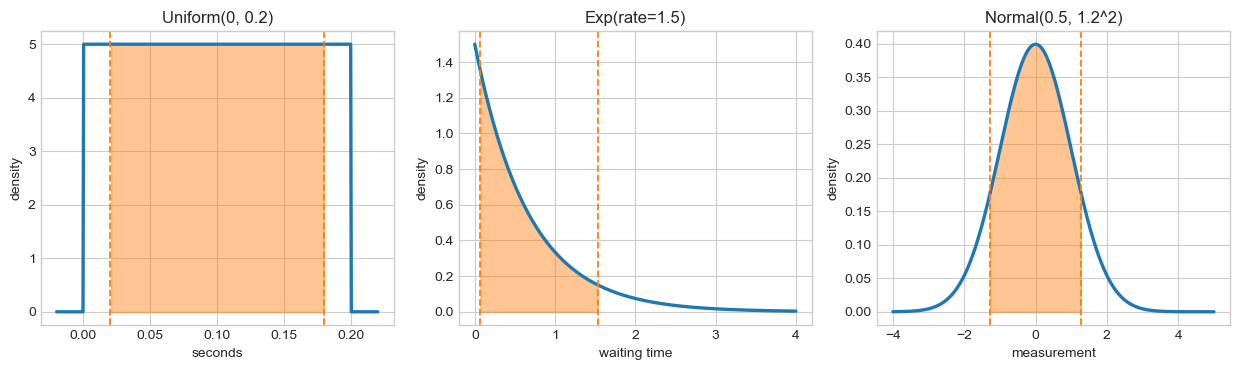

In [32]:
lambda_ = 1.5
mu, sigma = 0., 1

exponential = stats.expon(scale=1 / lambda_)
normal = stats.norm(loc=mu, scale=sigma)

continuous_models = [
    (short_uniform, np.linspace(-0.02, 0.22, 500), "Uniform(0, 0.2)", "seconds"),
    (exponential, np.linspace(0, 4, 500), "Exp(rate=1.5)", "waiting time"),
    (normal, np.linspace(-4, 5, 500), "Normal(0.5, 1.2^2)", "measurement"),
]

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for ax, (distribution, grid, title, xlabel) in zip(axes.flat, continuous_models):
    density = distribution.pdf(grid)
    lower, upper = distribution.ppf([0.1, 0.9])
    ax.plot(grid, density, color="tab:blue", linewidth=2.4)
    in_central_region = (grid >= lower) & (grid <= upper)
    ax.fill_between(grid[in_central_region], density[in_central_region], color="tab:orange", alpha=0.45)
    ax.axvline(lower, color="tab:orange", linestyle="--", linewidth=1.3)
    ax.axvline(upper, color="tab:orange", linestyle="--", linewidth=1.3)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("density")
plt.tight_layout()
plt.show()

## 3. PDF, CDF, survival function, and quantiles

For upper-tail probabilities, `sf` is preferable to subtracting a CDF close to one. The `ppf` method is the quantile function.

PDF at 1.5: 0.099574 per time unit
CDF at 1.5: 0.950213
survival probability beyond 1.5: 0.049787
q_0.1 = 0.052680
q_0.5 = 0.346574
q_0.9 = 1.151293


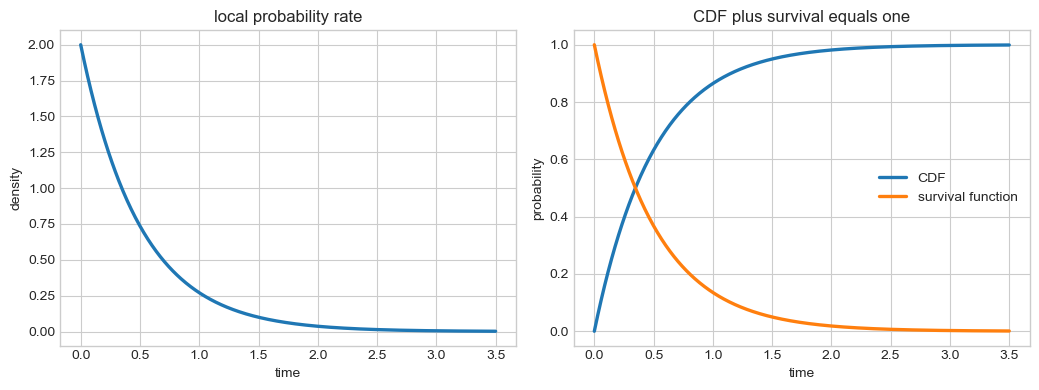

In [15]:
lambda_ = 2.0
exponential = stats.expon(scale=1 / lambda_)
threshold = 1.5
u_values = np.array([0.1, 0.5, 0.9])
quantiles = exponential.ppf(u_values)

print(f"PDF at {threshold}: {exponential.pdf(threshold):.6f} per time unit")
print(f"CDF at {threshold}: {exponential.cdf(threshold):.6f}")
print(f"survival probability beyond {threshold}: {exponential.sf(threshold):.6f}")
for probability, quantile in zip(u_values, quantiles):
    print(f"q_{probability:.1f} = {quantile:.6f}")

time_grid = np.linspace(0, 3.5, 600)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
axes[0].plot(time_grid, exponential.pdf(time_grid), linewidth=2.4, label="PDF")
axes[0].set_xlabel("time")
axes[0].set_ylabel("density")
axes[0].set_title("local probability rate")
axes[1].plot(time_grid, exponential.cdf(time_grid), linewidth=2.4, label="CDF")
axes[1].plot(time_grid, exponential.sf(time_grid), linewidth=2.4, label="survival function")
axes[1].set_xlabel("time")
axes[1].set_ylabel("probability")
axes[1].set_title("CDF plus survival equals one")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Fresh and remaining waits: does memorylessness hold?

For an elapsed time $s\geq0$ with $\mathbb P(T>s)>0$, retain only observations with $T>s$ and subtract $s$. The resulting observations are remaining waits, drawn from the conditional law of $T-s$ given $T>s$.

For $T\sim\operatorname{Exp}(\lambda)$, with $\lambda>0$, the remaining waits have survival probability $e^{-\lambda t}$ for every $t\geq0$, just like fresh waits. For $T\sim\operatorname{Unif}(0,1)$ and $0\leq s<1$, the corresponding conditional survival probability is
\[
\mathbb P(T>s+t\mid T>s)=
\begin{cases}
(1-s-t)/(1-s), & 0\leq t\leq1-s,\\
0, & t>1-s.
\end{cases}
\]
Thus the uniform model is not memoryless.

An empirical survival curve gives the fraction of observations strictly above each threshold. The plots check the formulas numerically; they do not replace the proof. The histogram uses all remaining exponential waits for normalization; only the displayed horizontal range is restricted.

Retained exponential waits: 44714 of 200000
Monte Carlo P(T > s+t | T > s): 0.36680
Monte Carlo P(T > t):         0.36854
Theoretical exp(-lambda*t):  0.36788


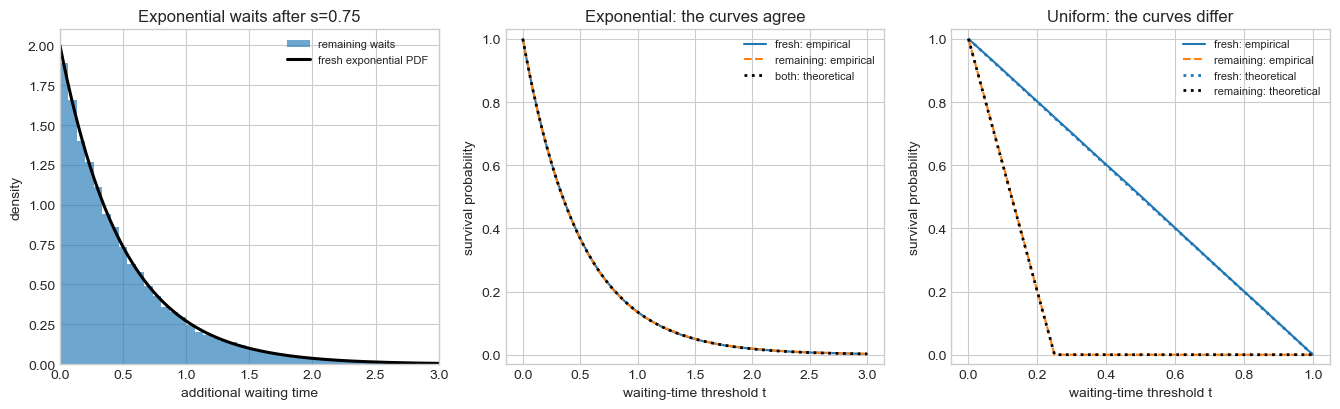

In [18]:
def empirical_survival(sample, thresholds):
    """Fraction of sample values strictly above each threshold."""
    sorted_sample = np.sort(sample)
    if sorted_sample.size == 0:
        raise ValueError("The empirical survival curve needs a nonempty sample.")
    return 1.0 - np.searchsorted(sorted_sample, thresholds, side="right") / sorted_sample.size


n_samples = 200_000
lambda_ = 2.0
exponential = stats.expon(scale=1 / lambda_)
waiting_sample = exponential.rvs(size=n_samples, random_state=rng)
s, t = 0.75, 0.50
survived_s = waiting_sample > s
residual_sample = waiting_sample[survived_s] - s
conditional_mc = (residual_sample > t).mean()
fresh_mc = (waiting_sample > t).mean()
theoretical = exponential.sf(t)

print(f"Retained exponential waits: {residual_sample.size} of {n_samples}")
print(f"Monte Carlo P(T > s+t | T > s): {conditional_mc:.5f}")
print(f"Monte Carlo P(T > t):         {fresh_mc:.5f}")
print(f"Theoretical exp(-lambda*t):  {theoretical:.5f}")

uniform_waiting = stats.uniform(loc=0.0, scale=1.0)
uniform_waits = uniform_waiting.rvs(size=n_samples, random_state=rng)
uniform_residual_sample = uniform_waits[uniform_waits > s] - s

residual_grid = np.linspace(0, 3, 500)
uniform_grid = np.linspace(0, 1, 500)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

# Normalize using the entire sample, not only the displayed range.
axes[0].hist(residual_sample, bins=80, density=True, alpha=0.65,
             color="tab:blue", label="remaining waits")
axes[0].plot(residual_grid, exponential.pdf(residual_grid), color="black",
             linewidth=2.2, label="fresh exponential PDF")
axes[0].set_xlim(0, 3)
axes[0].set_xlabel("additional waiting time")
axes[0].set_ylabel("density")
axes[0].set_title(f"Exponential waits after s={s:g}")
axes[0].legend(fontsize=8)

axes[1].plot(residual_grid, empirical_survival(waiting_sample, residual_grid),
             color="tab:blue", label="fresh: empirical")
axes[1].plot(residual_grid, empirical_survival(residual_sample, residual_grid),
             color="tab:orange", linestyle="--", label="remaining: empirical")
axes[1].plot(residual_grid, exponential.sf(residual_grid), color="black",
             linestyle=":", linewidth=2.0, label="both: theoretical")
axes[1].set_title("Exponential: the curves agree")
axes[1].set_xlabel("waiting-time threshold t")
axes[1].set_ylabel("survival probability")
axes[1].legend(fontsize=8)

axes[2].plot(uniform_grid, empirical_survival(uniform_waits, uniform_grid),
             color="tab:blue", label="fresh: empirical")
axes[2].plot(uniform_grid, empirical_survival(uniform_residual_sample, uniform_grid),
             color="tab:orange", linestyle="--", label="remaining: empirical")
axes[2].plot(uniform_grid, uniform_waiting.sf(uniform_grid), color="tab:blue",
             linestyle=":", linewidth=2.0, label="fresh: theoretical")
axes[2].plot(uniform_grid, uniform_waiting.sf(s + uniform_grid) / uniform_waiting.sf(s),
             color="black", linestyle=":", linewidth=2.0, label="remaining: theoretical")
axes[2].set_title("Uniform: the curves differ")
axes[2].set_xlabel("waiting-time threshold t")
axes[2].set_ylabel("survival probability")
axes[2].legend(fontsize=8)

for ax in axes[1:]:
    ax.set_ylim(-0.03, 1.03)
plt.tight_layout()
plt.show()

## 5. Normal location, scale, and quantiles

Let $\mu\in\mathbb R$ and $\sigma>0$. If $Z$ is standard normal and $X=\mu+\sigma Z$, quantiles transform by the same location-scale rule. For every $u\in(0,1)$, write $z_u=\Phi^{-1}(u)$ for a standard-normal quantile. Lecture 15 states and applies the central limit theorem without proof; the plots here do not establish it.

u       standard z_u    mu + sigma*z_u    SciPy normal ppf
0.025      -1.959964         5.100090           5.100090
0.500       0.000000        10.000000          10.000000
0.975       1.959964        14.899910          14.899910


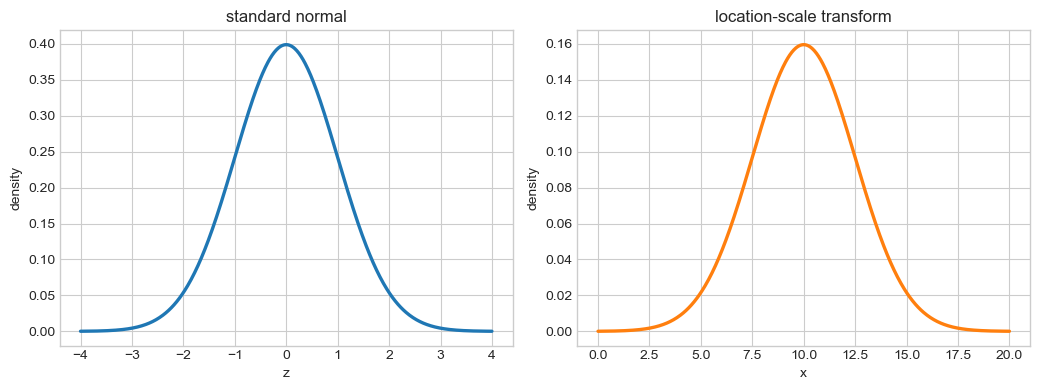

In [21]:
standard_normal = stats.norm(loc=0.0, scale=1.0)
mu, sigma = 10.0, 2.5
normal = stats.norm(loc=mu, scale=sigma)
u_values = np.array([0.025, 0.5, 0.975])
standard_quantiles = standard_normal.ppf(u_values)
transformed_quantiles = mu + sigma * standard_quantiles

print("u       standard z_u    mu + sigma*z_u    SciPy normal ppf")
for probability, z_quantile, x_quantile, scipy_quantile in zip(
    u_values, standard_quantiles, transformed_quantiles, normal.ppf(u_values)
):
    print(f"{probability:0.3f}   {z_quantile:12.6f}   {x_quantile:14.6f}   {scipy_quantile:16.6f}")

z_grid = np.linspace(-4, 4, 600)
x_grid = mu + sigma * z_grid
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
axes[0].plot(z_grid, standard_normal.pdf(z_grid), linewidth=2.4)
axes[0].set_title("standard normal")
axes[0].set_xlabel("z")
axes[0].set_ylabel("density")
axes[1].plot(x_grid, normal.pdf(x_grid), linewidth=2.4, color="tab:orange")
axes[1].set_title("location-scale transform")
axes[1].set_xlabel("x")
axes[1].set_ylabel("density")
plt.tight_layout()
plt.show()

## Exercise triad

*Presentation format:* Define the objects and assumptions, show the intermediate argument or computation, and finish with a clear conclusion. For the Python/data task, bring your code and present the results by walking through the code and explaining the output.

1. **Conceptual: changing temperature units.** Let $X$ denote the numerical value of a temperature measurement in degrees Celsius. Model $X\sim\operatorname{Unif}(19.5,20.5)$, using the density $f_X(x)\coloneqq\mathbf 1_{[19.5,20.5]}(x)$ for every $x\in\mathbb R$. The same temperature in degrees Fahrenheit is $Y\coloneqq\frac95X+32$.
    1. Sketch $f_X$ with labeled axes and units, verify by integration that it is normalized, and compute $f_X(20)$, $\mathbb P(X=20)$, and $\mathbb P(19.75\le X\le20.25)$.
    2. For every $y\in\mathbb R$, express $\{Y\le y\}$ as an event involving $X$. Derive $F_Y$, and use the location-scale formula with the chosen $f_X$ to obtain a density $f_Y$. State its support and sketch its graph with labeled axes and units.
    3. Convert the Celsius interval $[19.75,20.25]$ to Fahrenheit and compute the corresponding interval probability using $f_Y$. Compare $f_X(20)$ with $f_Y(68)$. Describe separately the effects of the shift by $32$ and the scaling by $9/5$ on the density graph. Explain why density heights depend on the measurement units, whereas probabilities of corresponding events do not.
2. **Mathematical:** Normalize $f(x)=c(1-x)\mathbf 1_{[0,1]}(x)$, then derive its CDF, quantile function, and 0.9-quantile.
3. **Python/data:** Use `lecture_06_examples.ipynb` as a starting point. Simulate 30,000 independent waiting times with law $\operatorname{Exp}(2)$. Fix $s=0.5$; retain only waits exceeding $s$, then subtract $s$ to obtain the remaining waits. Plot the empirical survival curves of the original and remaining waits together with $e^{-2t}$ for $t\geq0$. For both samples, tabulate the empirical 0.1, 0.5, and 0.9 quantiles alongside the exponential quantiles, using `method="inverted_cdf"` in `np.quantile`. Report the largest absolute discrepancy from the theoretical survival curve on a stated finite grid. Repeat the survival-curve comparison for 30,000 independent waits with law $\operatorname{Unif}(0,1)$, keeping $s=0.5$, and derive $\mathbb P(T>s+t\mid T>s)$ for every $t\geq0$ under that model. Explain why the two models behave differently and identify SciPy's reciprocal-rate argument.